# Faz 5 — Modelleme

**Görev:** Bir oyunun **çıkış öncesi** bilinebilecek özelliklerinden, "iyi karşılanıp
karşılanmayacağını" (yeterli review alması durumunda `positive_ratio >= 0.8`) tahmin etmeye
çalışıyoruz. Veri sızıntısına özellikle dikkat ediyoruz: sadece çıkıştan önce bilinebilecek
özellikler kullanılıyor, review/sahip sayısı/oynama süresi gibi çıkış-sonrası metrikler
**kullanılmıyor**.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from src.plots import set_style, save_fig, CATEGORICAL_PALETTE
from src.features import multi_hot_encode

set_style()
pd.set_option('display.max_columns', 100)
RANDOM_STATE = 42

df = pd.read_parquet('../data/processed/games_clean.parquet')
enough = df[df['has_enough_reviews']].copy()
enough['target'] = (enough['positive_ratio'] >= 0.8).astype(int)
print(f"Modelleme veri kümesi (yeterli review'u olan oyunlar): {len(enough):,}")
print(f"Hedef dağılımı: {enough['target'].value_counts(normalize=True).to_dict()}")

Modelleme veri kümesi (yeterli review'u olan oyunlar): 56,691
Hedef dağılımı: {1: 0.5348644405637579, 0: 0.4651355594362421}


## Hedef ve Eşik

`positive_ratio >= 0.8` eşiği Faz 2'deki `review_label` sınıflandırmasındaki "Very Positive" ve
üzeri sınırla aynı — yani hedef, pratikte "oyun en az 'Very Positive' seviyesinde karşılandı mı?"
sorusuna karşılık geliyor. Sınıf dengesi makul (~%53 / %47), ağır bir dengesizlik yok.

## Kullanılan ve Dışlanan Özellikler

| Kategori | Kullanıldı mı? | Açıklama |
|---|---|---|
| `price`, `dlc_count`, `required_age` | ✅ | Listeleme anında bilinir |
| `num_languages`, `windows`, `mac`, `linux` | ✅ | Çıkış öncesi planlanır |
| `num_genres`, en sık 15 tür (multi-hot) | ✅ | Steam listelemesinde atanır |
| `num_categories`, en sık 15 kategori (multi-hot) | ✅ | Steam listelemesinde atanır (Single-player, Steam Achievements, ...) |
| `achievements` (başarım **sayısı**) | ✅ | Geliştirici tasarım kararı, çıkıştan önce belirlenir |
| `description_length` | ✅ | Mağaza sayfası metni, çıkıştan önce yazılır |
| `release_month`, `release_year` | ✅ | Çıkış tarihi planlaması |
| `is_self_published` | ✅ | Yayıncı anlaşması çıkıştan önce belli olur |
| `tags_list` (etiketler) | ❌ **dışlandı** | Doküman bunu izin verilen listede sayıyor, ama **tags topluluk tarafından oyun yayınlandıktan sonra oy verilerek oluşuyor** (bkz. Faz 1-2) — sayısı/içeriği doğrudan oyunun popülerliğinin bir *sonucu*. Çıkıştan önce bilinemez; dahil etmek sızıntı riski taşır. |
| `has_publisher` (yayıncı var mı) | ❌ **dışlandı** | Oyunların %99,3'ü (kendi yayıncısı dahil) bu alanda dolu — neredeyse sıfır varyans, ayırt edici değil. Onun yerine `is_self_published` kullanıldı. |
| `positive`, `negative`, `total_reviews`, `owners_*`, `peak_ccu`, `average_playtime_*`, `metacritic_score`, `user_score`, `recommendations` | ❌ **dışlandı (sızıntı)** | Hepsi çıkış **sonrası** oluşan metrikler; hedefin kendisiyle veya onun bileşenleriyle doğrudan ilişkili. |


In [2]:
FEATURE_BASE_COLS = [
    'price', 'dlc_count', 'num_languages', 'windows', 'mac', 'linux',
    'num_genres', 'num_categories', 'achievements', 'description_length',
    'release_month', 'release_year', 'required_age', 'is_self_published',
]
TOP_N_GENRES = 15
TOP_N_CATEGORIES = 15


def build_features(frame, top_genres, top_cats):
    base = frame[FEATURE_BASE_COLS].copy()
    for col in ['windows', 'mac', 'linux', 'is_self_published']:
        base[col] = base[col].astype(int)
    genre_cols = pd.DataFrame(
        {f'genre_{g}': frame['genres'].apply(lambda lst, g=g: int(g in lst)) for g in top_genres},
        index=frame.index,
    )
    cat_cols = pd.DataFrame(
        {f'cat_{c}': frame['categories'].apply(lambda lst, c=c: int(c in lst)) for c in top_cats},
        index=frame.index,
    )
    return pd.concat([base, genre_cols, cat_cols], axis=1)


def evaluate(name, y_true, y_pred, y_proba):
    return {
        'model': name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, y_proba),
    }

## Train/Test Ayrımı: Zaman-Bazlı (Esas) vs Rastgele (Karşılaştırma)

Doküman önerisi gereği önce **zamana göre** ayırıyoruz (2022 ve öncesiyle eğit, 2023+ ile test
et) — bu, gerçek dünyada "yeni çıkan bir oyunun başarısını tahmin etme" senaryosunu simüle
ediyor. Ardından aynı özelliklerle **rastgele %80/%20** ayrımı yapıp karşılaştırıyoruz.

In [3]:
train_df = enough[enough['release_year'] <= 2022].copy()
test_df = enough[enough['release_year'] >= 2023].copy()
print(f"Zaman-bazlı: train={len(train_df):,} (<=2022), test={len(test_df):,} (>=2023)")
print(f"Train hedef oranı: {train_df['target'].mean():.1%} | Test hedef oranı: {test_df['target'].mean():.1%}")

Zaman-bazlı: train=40,930 (<=2022), test=15,761 (>=2023)
Train hedef oranı: 48.2% | Test hedef oranı: 67.3%


**Önemli gözlem:** Train döneminde hedef oranı %48 iken test döneminde %67'ye çıkıyor —
yıllar arasında "Very Positive ve üzeri" oyun oranı belirgin şekilde artmış (bkz. Faz 3/4'teki
büyüme ve eşik tartışmaları; ayrıca yakın yıllarda zaten 10+ review toplamış oyunların,
"hızlı tutunan" ve dolayısıyla nispeten iyi karşılanan oyunlar olması da bir seçilim etkisi
olabilir). Bu kayma, saf çoğunluk-sınıfı taban çizgisinin test setinde **düşük** çıkmasına yol
açacak (çünkü train'deki çoğunluk sınıf test'te azınlık) — bu bir model hatası değil, zamanla
değişen bir temel oran meselesi; bu yüzden tek başına accuracy yerine F1 ve ROC-AUC'a da
bakıyoruz.

In [4]:
genre_enc_train, top_genres = multi_hot_encode(train_df, 'genres', top_n=TOP_N_GENRES)
cat_enc_train, top_cats = multi_hot_encode(train_df, 'categories', top_n=TOP_N_CATEGORIES)

X_train = build_features(train_df, top_genres, top_cats)
X_test = build_features(test_df, top_genres, top_cats)
y_train = train_df['target'].values
y_test = test_df['target'].values
print('Özellik sayısı:', X_train.shape[1])

Özellik sayısı: 44


## Modeller: Baseline, Logistic Regression, Random Forest, XGBoost

In [5]:
results = []

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
results.append(evaluate('Baseline (çoğunluk sınıfı)', y_test, dummy.predict(X_test), dummy.predict_proba(X_test)[:, 1]))

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_scaled, y_train)
results.append(evaluate('Logistic Regression', y_test, logreg.predict(X_test_scaled), logreg.predict_proba(X_test_scaled)[:, 1]))

rf = RandomForestClassifier(n_estimators=300, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
results.append(evaluate('Random Forest', y_test, rf.predict(X_test), rf.predict_proba(X_test)[:, 1]))

xgb_model = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, random_state=RANDOM_STATE, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
results.append(evaluate('XGBoost', y_test, xgb_model.predict(X_test), xgb_model.predict_proba(X_test)[:, 1]))

results_df = pd.DataFrame(results).set_index('model').round(3)
results_df

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Baseline (çoğunluk sınıfı),0.327,0.000,0.000,0.000,0.500
Logistic Regression,0.676,0.726,0.834,0.776,0.654
Random Forest,0.667,0.748,0.762,0.755,0.680
XGBoost,0.680,0.756,0.775,0.765,0.695


Tüm modeller baseline'ı ROC-AUC'ta açıkça geçiyor (0.50 → ~0.65-0.70) ama hiçbiri çok
yüksek bir performansa ulaşmıyor. **XGBoost** ROC-AUC'ta en iyi sonucu veriyor (≈0.70); onu
Random Forest (≈0.68) ve Logistic Regression (≈0.65) izliyor. Baseline'ın accuracy'si düşük
(%33 civarı) ama bu yukarıda açıklanan taban-oranı kaymasından kaynaklanıyor, "kötü model"
anlamına gelmiyor.

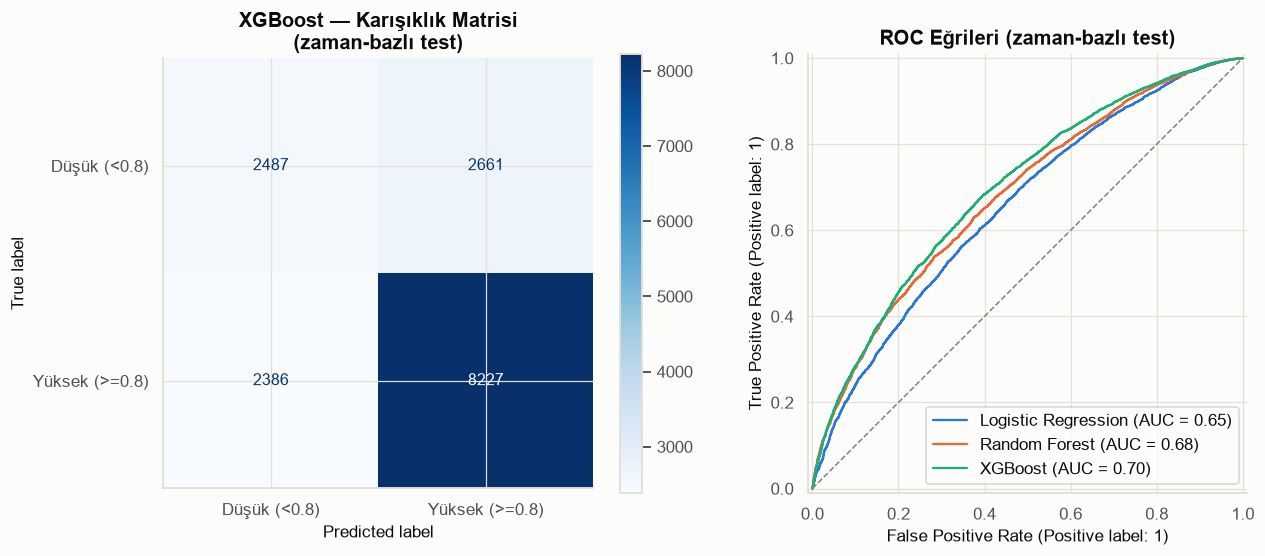

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    xgb_model, X_test, y_test, ax=axes[0], cmap='Blues',
    display_labels=['Düşük (<0.8)', 'Yüksek (>=0.8)'],
)
axes[0].set_title('XGBoost — Karışıklık Matrisi\n(zaman-bazlı test)')

for name, model, proba_fn in [
    ('Logistic Regression', logreg, lambda m: m.predict_proba(X_test_scaled)[:, 1]),
    ('Random Forest', rf, lambda m: m.predict_proba(X_test)[:, 1]),
    ('XGBoost', xgb_model, lambda m: m.predict_proba(X_test)[:, 1]),
]:
    RocCurveDisplay.from_predictions(y_test, proba_fn(model), name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
axes[1].set_title('ROC Eğrileri (zaman-bazlı test)')

fig.tight_layout()
save_fig(fig, '05_01_karisiklik_matrisi_ve_roc')
plt.show()

Karışıklık matrisi, modelin "yüksek" sınıfı (pozitif) oldukça iyi yakaladığını ama
"düşük" sınıfta daha fazla hata yaptığını gösteriyor — bu da test döneminde "yüksek" sınıfın
çoğunluk olmasıyla tutarlı. ROC eğrilerinde üç model de rastgele tahminin (kesikli çizgi)
belirgin şekilde üzerinde ama mükemmelden çok uzak; eğriler birbirine yakın, hiçbir model
diğerlerinden çarpıcı şekilde üstün değil.

## Zaman-Bazlı vs Rastgele Ayrım Karşılaştırması

In [7]:
train_r, test_r = train_test_split(enough, test_size=0.2, random_state=RANDOM_STATE, stratify=enough['target'])
genre_enc_r, top_genres_r = multi_hot_encode(train_r, 'genres', top_n=TOP_N_GENRES)
cat_enc_r, top_cats_r = multi_hot_encode(train_r, 'categories', top_n=TOP_N_CATEGORIES)

X_train_r = build_features(train_r, top_genres_r, top_cats_r)
X_test_r = build_features(test_r, top_genres_r, top_cats_r)
y_train_r = train_r['target'].values
y_test_r = test_r['target'].values

xgb_r = xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, random_state=RANDOM_STATE, eval_metric='logloss')
xgb_r.fit(X_train_r, y_train_r)
xgb_random_metrics = evaluate('XGBoost (rastgele ayrım)', y_test_r, xgb_r.predict(X_test_r), xgb_r.predict_proba(X_test_r)[:, 1])
xgb_time_metrics = {**results_df.loc['XGBoost'].to_dict(), 'model': 'XGBoost (zaman-bazlı)'}

pd.DataFrame([xgb_time_metrics, xgb_random_metrics]).set_index('model').round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
XGBoost (zaman-bazlı),0.680,0.756,0.775,0.765,0.695
XGBoost (rastgele ayrım),0.677,0.688,0.725,0.706,0.744


Rastgele ayrımda ROC-AUC belirgin şekilde daha yüksek çıkıyor (~0.74 vs ~0.70) — çünkü
rastgele ayrımda train ve test, aynı zaman diliminden karışık örnekler içeriyor (dolayısıyla
daha "benzer"), zaman-bazlı ayrım ise modelin hiç görmediği, farklı bir döneme genelleme
yapmasını istiyor. **Zaman-bazlı sonuç, gerçek kullanım senaryosunu (henüz çıkmamış bir oyunu
tahmin etmek) daha doğru yansıtıyor ve bu yüzden asıl referans olarak o alınmalı** — rastgele
ayrım sonucu iyimser bir üst sınır olarak düşünülmeli.

## SHAP ile Özellik Önemleri (XGBoost, en iyi zaman-bazlı model)

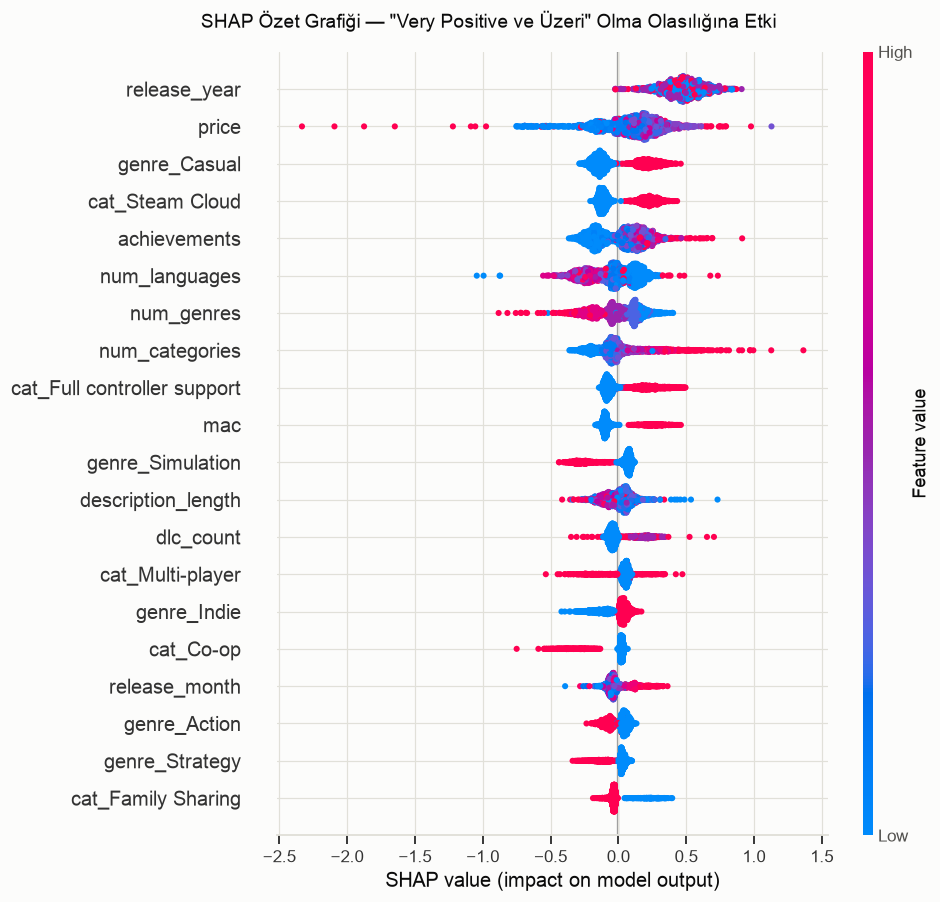

In [8]:
sample = X_test.sample(min(2000, len(X_test)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(sample)
# Bazı model/ikili-sınıflandırma kombinasyonlarında (n, özellik, sınıf) şekli dönebilir;
# bu durumda pozitif sınıfı (indeks 1) alıyoruz, XGBoost için doğrudan 2 boyutlu gelir.
shap_values = np.array(shap_values)
shap_positive = shap_values[:, :, 1] if shap_values.ndim == 3 else shap_values

fig = plt.figure(figsize=(9, 8))
shap.summary_plot(shap_positive, sample, show=False, plot_size=None)
fig = plt.gcf()
fig.suptitle('SHAP Özet Grafiği — "Very Positive ve Üzeri" Olma Olasılığına Etki', y=1.02)
save_fig(fig, '05_02_shap_ozet')
plt.show()

In [9]:
mean_abs_shap = pd.Series(np.abs(shap_positive).mean(axis=0), index=sample.columns).sort_values(ascending=False)
mean_abs_shap.head(15)

release_year                   0.481806
price                          0.202139
genre_Casual                   0.173284
cat_Steam Cloud                0.162691
achievements                   0.154667
num_languages                  0.142198
num_genres                     0.135782
num_categories                 0.131406
cat_Full controller support    0.127026
mac                            0.121115
genre_Simulation               0.119743
description_length             0.075246
dlc_count                      0.075167
cat_Multi-player               0.069561
genre_Indie                    0.069008
dtype: float32

En yüksek ortalama |SHAP| değerine sahip özellik yine **`release_year`** — ama kendi
değeriyle SHAP katkısı arasındaki korelasyon zayıf (yaklaşık -0.03), yani etkisi basit
"daha yeni = daha başarılı" gibi tek yönlü değil; muhtemelen "Zaman-Bazlı vs Rastgele"
bölümünde gördüğümüz **taban oranı kaymasının** bir kısmını yakalıyor, temiz bir tasarım
faktörü değil. Ondan sonra **`price`** (zayıf negatif, korelasyon ≈ -0.17 — biraz daha düşük
fiyat hafifçe daha yüksek başarı olasılığıyla ilişkili), **`genre_Casual`** ve
**`cat_Steam Cloud`** (ikisi de güçlü pozitif, korelasyon ≈ 0.95) ve **`achievements`**
(pozitif, korelasyon ≈ 0.68 — daha fazla başarım, daha yüksek olasılık) geliyor.
**`num_genres`** negatif yönde (korelasyon ≈ -0.89) — çok sayıda türe yayılmak yerine
odaklı bir pozisyonlama daha olumlu görünüyor; **`num_categories`** ise tam tersine pozitif
(≈ 0.90). Yine de hiçbir özelliğin etkisi tek başına baskın değil; SHAP değerleri birçok
orta-küçük etkinin toplamından oluşuyor. **Gerçekçi yorum:** Çıkış-öncesi bilinebilen
özellikler, bir oyunun "Very Positive" seviyesine ulaşıp ulaşmayacağını **sınırlı ama gerçek**
ölçüde açıklıyor (ROC-AUC ~0.70, rastgele tahminin belirgin üzerinde ama mükemmelden çok uzak).
Bu düşük-orta performansın kendisi önemli bir bulgu: **oyun kalitesi/karşılanma biçimi,
listeleme sayfasındaki özelliklerden çok daha fazlasına (oynanış kalitesi, pazarlama
zamanlaması, şans, topluluk dinamikleri gibi veri setinde yakalanamayan faktörlere) bağlı**
görünüyor.

## Faz 5 Özeti

- Hedef: yeterli review'u olan oyunlarda `positive_ratio >= 0.8` ("Very Positive ve üzeri").
- Veri sızıntısından kaçınmak için sadece çıkış-öncesi bilinebilen özellikler kullanıldı;
  `tags` (topluluk kaynaklı) ve neredeyse sıfır varyanslı `has_publisher` bilinçli olarak dışlandı.
- Zaman-bazlı ayrımda train/test arasında hedef oranı belirgin şekilde kaydı (%48 → %67) —
  bu durum baseline accuracy'yi yanıltıcı şekilde düşük gösteriyor, bu yüzden F1/ROC-AUC esas alındı.
- **XGBoost** (ROC-AUC ≈ 0.70) zaman-bazlı testte en iyi model; Random Forest ve Logistic
  Regression yakın ama biraz daha düşük performansta.
- Rastgele ayrım (ROC-AUC ≈ 0.74) zaman-bazlı ayrımdan daha iyimser sonuç veriyor — gerçek
  kullanım senaryosu için zaman-bazlı sonuç esas alınmalı.
- SHAP analizi `release_year` (muhtemelen taban oranı kaymasını yakalıyor), `genre_Casual` ve
  `cat_Steam Cloud` (pozitif), `achievements` (pozitif), `num_genres` (negatif — odaklı
  pozisyonlama) gibi sinyallerin öne çıktığını gösteriyor, ama hiçbiri tek başına baskın değil.
- **Genel sonuç:** Çıkış-öncesi özellikler başarıyı yalnızca sınırlı ölçüde açıklıyor — bu,
  başarının büyük kısmının oynanış kalitesi, pazarlama ve şans gibi bu veri setinde doğrudan
  ölçülemeyen faktörlere bağlı olduğunu düşündürüyor.